# 고객 이탈 예측 — 분류 모델 고도화 · 검증 및 평가 종합 실습

수업 필기 `고객이탈예측_1` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `모델검증및평가` 18장 — 분류 모델 성능 고도화 검증 및 평가 종합 실습, `머신러닝` v7 p.138~146 — GridSearchCV · RandomizedSearchCV)

- 같은 데이터로 처음 모델을 만든 날은 [Day 026](../../2026-10-15/), 평가 지표 · 특성 중요도 개념은 [Day 029](../../2026-10-20/) 에 정리했습니다. 오늘은 그 둘을 합쳐 **튜닝 → 평가 → 특성 중요도로 검증**까지 한 번에 합니다.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.
- 회귀 종합 실습(보스턴 집값)은 [`regression_model_evaluation.ipynb`](./regression_model_evaluation.ipynb) 에 있습니다.

> 데이터 : `Telco-Customer-Churn.csv` (통신사 고객 7,043명 × 21열, 정답 `Churn` = 이탈 Yes / No). 컬럼 설명은 [Day 026 의 데이터 설명서](../../2026-10-15/lecture/).

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 데이터 불러오기 · 전처리

In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv('./Telco-Customer-Churn.csv')     # 노트북과 같은 폴더
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 문제점 : TotalCharges 는 숫자여야 하는데 공백 문자열(' ') 이 섞여 문자열로 읽혔다
space_index = df.query("TotalCharges == ' '").index
print("공백인 행 :", space_index.tolist())
print("그 고객들의 가입 기간(tenure) :", df.loc[space_index, 'tenure'].unique())   # 모두 0 → 아직 첫 요금 청구 전

# 1단계 : 문자열 → 숫자 (숫자로 바꿀 수 없는 값은 NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# 2단계 : 누락 행 제거
df1 = df.dropna(ignore_index=True)
print(df.shape, '->', df1.shape)

공백인 행 : [488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754]
그 고객들의 가입 기간(tenure) : [0]
(7043, 21) -> (7032, 21)


> **📝 고친 부분** (`고객이탈예측_1`)
> - 경로 `C:/Users/playdata2/work/...` → 노트북과 같은 폴더 `./Telco-Customer-Churn.csv`
> - `print(space_index)` 셀에 저장된 출력이 없었다(실행 순서가 섞인 흔적) → 공백 11건과 그 고객들이 모두 **`tenure = 0`(신규 가입)** 인 것까지 확인
> - `df.info()` 를 두 번 찍던 것 → `dtype` 변화는 한 줄로 충분, `display(df1)` 7천 행 출력 → 모양만
> - 주석 오타 `변환활` → 변환할
> - `warnings.filterwarnings('ignore')` 를 맨 앞에 두면 **중요한 경고까지 숨는다** — 아래 4장의 `ConvergenceWarning` 이 바로 그 예. 이 노트는 경고를 끄지 않았다.

## 2. EDA — 어떤 고객이 떠나는가

필기의 plotly 그래프 5개(이탈 비율 · 계약 형태 · 가입 기간 · 월 요금 · 총 요금)를 GitHub 에서도 보이도록 matplotlib 한 장으로 그렸다.

{'No': 0.7342, 'Yes': 0.2658}
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48


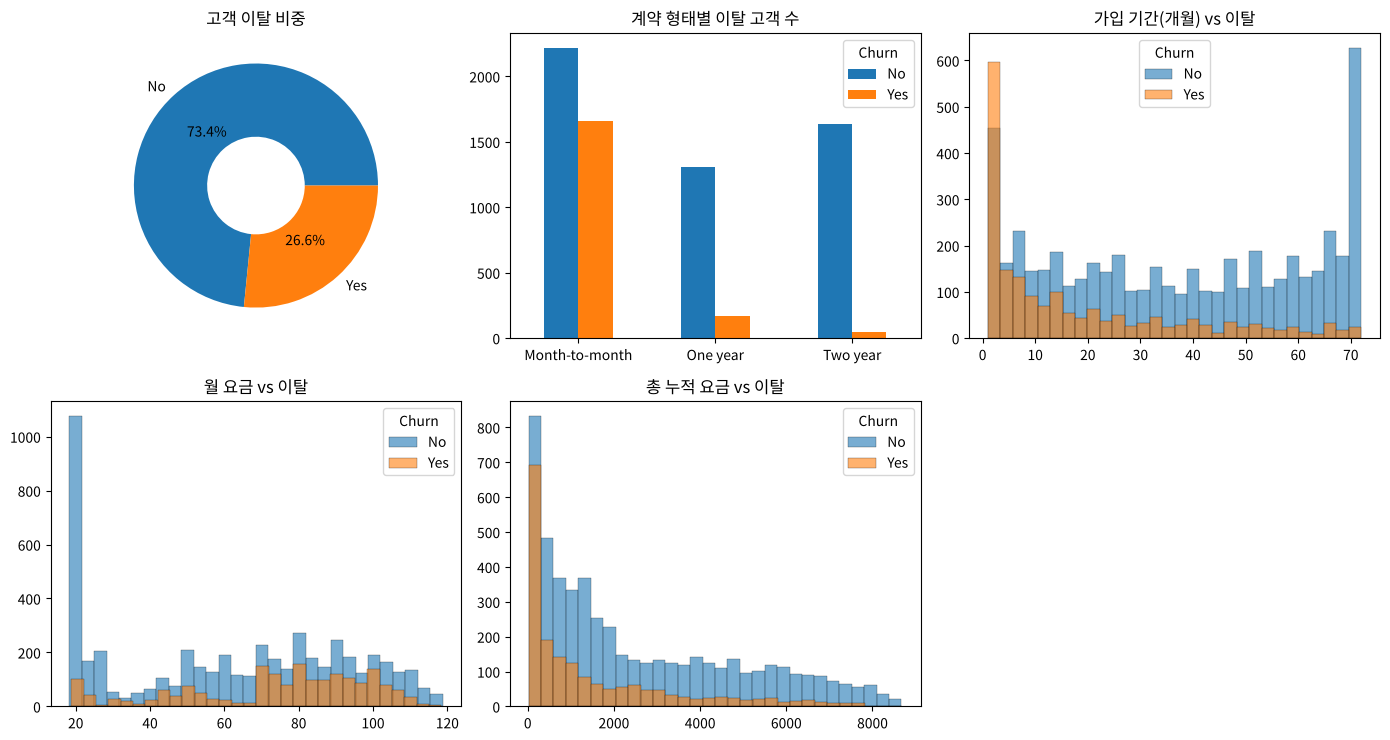

In [4]:
churn_ratio = df1['Churn'].value_counts(normalize=True)
contract = df1.groupby(['Contract', 'Churn']).size().unstack()
print(churn_ratio.round(4).to_dict())
print(contract)

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
axes = axes.ravel()
axes[0].pie(churn_ratio, labels=churn_ratio.index, autopct='%.1f%%', wedgeprops=dict(width=0.6))
axes[0].set_title('고객 이탈 비중')
contract.plot.bar(ax=axes[1], rot=0)
axes[1].set_title('계약 형태별 이탈 고객 수'); axes[1].set_xlabel('')
for ax, col, title in zip(axes[2:5], ['tenure', 'MonthlyCharges', 'TotalCharges'],
                          ['가입 기간(개월)', '월 요금', '총 누적 요금']):
    for label in ['No', 'Yes']:
        ax.hist(df1.loc[df1['Churn'] == label, col], bins=30, alpha=0.6, label=label, edgecolor='black', linewidth=0.3)
    ax.set_title(f'{title} vs 이탈'); ax.legend(title='Churn')
axes[5].axis('off')
plt.tight_layout()
plt.show()

- 이탈 **26.6%** → 불균형. 전부 "유지"라고 찍어도 정확도 0.734 (기준선)
- 월 단위 계약은 3,875명 중 1,655명(**42.7%**) 이탈, 2년 계약은 2.8%
- 가입 **초기**에 이탈이 몰리고, 월 요금 70 ~ 105 구간에서 이탈이 많다

## 3. 인코딩 · 분리

In [5]:
df2 = df1.drop(columns=['customerID'])                      # 고객 번호는 예측에 쓸모없음
df2['Churn'] = df2['Churn'].map({'No': 0, 'Yes': 1})        # 정답 : 레이블 인코딩

# 범주형(문자열) 컬럼 이름 → 원-핫 인코딩
categorical_cols = df2.select_dtypes(include=['object', 'string']).columns.tolist()
print(len(categorical_cols), "개 :", categorical_cols)

df_onehot = pd.get_dummies(data=df2, columns=categorical_cols, dtype=int)
print(df2.shape, '->', df_onehot.shape)

15 개 : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(7032, 20) -> (7032, 46)


In [6]:
from sklearn.model_selection import train_test_split

X_data = df_onehot.drop(columns=['Churn'])
y_data = df_onehot['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data)

print("학습용 :", X_train.shape, " 평가용 :", X_test.shape)
print("X · y 인덱스 짝 :", (X_train.index == y_train.index).all())
print("이탈 비율  전체 / 학습용 / 평가용 :",
      round(y_data.mean(), 4), round(y_train.mean(), 4), round(y_test.mean(), 4))   # stratify 로 같게

학습용 : (5625, 45)  평가용 : (1407, 45)
X · y 인덱스 짝 : True
이탈 비율  전체 / 학습용 / 평가용 : 0.2658 0.2658 0.2658


> **📝 고친 부분**
> - `select_dtypes(include=['object'])` → `['object', 'string']` — pandas 3 에서는 문자열 자료형이 `str` 이라 `'object'` 만 쓰면 경고가 나고 앞으로 못 찾게 된다([Day 020 예시](../../2026-10-06/))
> - 학습용 이탈 비율을 출력하면서 제목은 **"평가용** 데이터의 정답 비율" → 학습용 · 평가용을 나란히

## 4. 로지스틱 회귀 — 필기 그대로 (스케일링 없음)

In [7]:
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    lr = LogisticRegression()
    lr.fit(X_train, y_train)

print("경고 :", {w.category.__name__ for w in caught})
print("반복 횟수 n_iter_ :", lr.n_iter_, "/ max_iter =", lr.max_iter, " ← 끝까지 돌고도 못 멈췄다")

pred_test_lr = lr.predict(X_test)
print(f"정확도 : {accuracy_score(y_test, pred_test_lr):.4f}")
print(classification_report(y_test, pred_test_lr))

경고 : {'ConvergenceWarning'}
반복 횟수 n_iter_ : [100] / max_iter = 100  ← 끝까지 돌고도 못 멈췄다
정확도 : 0.8067
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1033
           1       0.66      0.55      0.60       374

    accuracy                           0.81      1407
   macro avg       0.76      0.73      0.74      1407
weighted avg       0.80      0.81      0.80      1407



**`ConvergenceWarning`** — 최적의 가중치를 찾는 계산(lbfgs)이 100번 안에 **수렴하지 못했다**. 필기는 `warnings.filterwarnings('ignore')` 로 이 경고를 숨겨서 몰랐던 것.
원인은 [Day 026](../../2026-10-15/) 과 같다 — `TotalCharges`(0 ~ 8,684)와 0/1 원-핫 컬럼의 **단위 차이**. 수렴하지 못한 모델은 컴퓨터 · 라이브러리 버전마다 결과가 조금씩 달라진다(필기 0.8053, 이 노트 0.8067).

### 4-1. 필기의 "특성 중요도" — 스케일링 안 한 계수는 믿을 수 없다

필기는 `np.abs(lr.coef_[0])` 를 특성 중요도로 썼다. 그런데 계수(기울기)는 **특성이 1 단위 늘 때** 의 영향이라, 단위가 큰 특성일수록 계수가 작게 나온다.

In [8]:
coef_raw = pd.Series(np.abs(lr.coef_[0]), index=X_train.columns).sort_values(ascending=False)
print("필기 방식 상위 5개 :", coef_raw.head(5).round(3).to_dict())
print("숫자 컬럼들의 순위 :",
      {c: int(coef_raw.index.get_loc(c)) + 1 for c in ['tenure', 'TotalCharges', 'MonthlyCharges']}, "/ 45")
print(X_train[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().loc[['min', 'max', 'std']].round(1))

필기 방식 상위 5개 : {'Contract_Month-to-month': 0.451, 'Contract_Two year': 0.35, 'InternetService_DSL': 0.299, 'InternetService_Fiber optic': 0.285, 'PaymentMethod_Electronic check': 0.283}
숫자 컬럼들의 순위 : {'tenure': 35, 'TotalCharges': 45, 'MonthlyCharges': 43} / 45
     tenure  MonthlyCharges  TotalCharges
min     1.0            18.2          18.8
max    72.0           118.8        8684.8
std    24.5            30.0        2263.8


In [9]:
# 스케일링(평균 0 · 표준편차 1) 후 학습하면 계수끼리 비교할 수 있다
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lr_scaled = make_pipeline(StandardScaler(), LogisticRegression())
lr_scaled.fit(X_train, y_train)
print("반복 횟수 :", lr_scaled[-1].n_iter_, " ← 스케일링하면 금방 수렴")

coef_scaled = pd.Series(lr_scaled[-1].coef_[0], index=X_train.columns)
top = coef_scaled.abs().sort_values(ascending=False).head(8).index
compare = pd.DataFrame({'계수(부호 포함)': coef_scaled[top].round(3),
                        '필기 방식 순위': [int(coef_raw.index.get_loc(c)) + 1 for c in top]})
compare

반복 횟수 : [28]  ← 스케일링하면 금방 수렴


,계수(부호 포함),필기 방식 순위
tenure,-1.478,35
TotalCharges,0.777,45
Contract_Month-to-month,0.285,1
Contract_Two year,-0.273,2
InternetService_Fiber optic,0.164,4
InternetService_DSL,-0.143,3
PaymentMethod_Electronic check,0.130,5
TechSupport_No,0.113,7


| | 필기 (스케일링 X) | 스케일링 O |
|---|---|---|
| 1위 | `Contract_Month-to-month` · `Contract_Two year` | **`tenure`** (−1.48) |
| `tenure` 순위 | 45개 중 **35위** | **1위** |
| `TotalCharges` 순위 | 45개 중 **45위** (꼴찌) | **2위** (+0.78) |

- 스케일링 전 `tenure` 는 0 ~ 72, `TotalCharges` 는 0 ~ 8,684 라서 "1개월 · 1달러"당 영향이 작게 보였을 뿐이다.
- **부호**도 의미가 있다 : `tenure` 는 **−** (오래 쓴 고객일수록 덜 떠남), `TotalCharges` 는 **+** (같은 기간이면 많이 낸 고객이 더 떠남).
- 원-핫을 모든 값으로 만들면(`Contract_Month-to-month` · `One year` · `Two year`) 셋을 더하면 항상 1 이라 계수가 **서로 나눠 가진다** → 하나만 따로 해석하기 어렵다. 그래서 아래 6장의 **순열 특성 중요도**로 한 번 더 확인한다.

> **📝 고친 부분** — 주석 "학습 완료 후 생성된 최적의 **직선** 기울기" → 로지스틱 회귀에서 계수는 특성 45개 공간의 **결정 경계(초평면)** 방향이고, 계수 하나는 그 특성이 1 늘 때 **log-odds(이탈 확률의 로짓)** 가 얼마나 변하는지다.

## 5. 로지스틱 회귀 고도화 — `GridSearchCV`

### 5-1. 필기 그대로 : `C` × `max_iter`, `scoring='f1'`

In [10]:
from sklearn.model_selection import GridSearchCV

params = {
    'C': [0.01, 0.1, 1, 10, 100],          # 규제 강도의 역수 (작을수록 강한 규제)
    'max_iter': [100, 500, 1000, 5000],    # 계산 반복 횟수 상한
}                                          # 5 × 4 = 20가지

grid_lr = GridSearchCV(LogisticRegression(random_state=0), param_grid=params, scoring='f1', cv=5)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')        # 20 × 5 = 100번 학습에서 ConvergenceWarning 이 쏟아지므로 여기서만 끈다
    grid_lr.fit(X_train, y_train)

print("best :", grid_lr.best_params_, " 검증 F1 :", round(grid_lr.best_score_, 4))
pd.DataFrame(grid_lr.cv_results_).pivot(index='param_C', columns='param_max_iter', values='mean_test_score').round(4)

best : {'C': 100, 'max_iter': 500}  검증 F1 : 0.5981


param_max_iter,100,500,1000,5000
param_C,,,,
0.01,0.5875,0.5868,0.5857,0.5855
0.10,0.5939,0.5981,0.5963,0.5964
1.00,0.5955,0.5980,0.5952,0.5950
10.00,0.5926,0.5962,0.5952,0.5939
100.00,0.5934,0.5981,0.5960,0.5943


- `max_iter` 는 모델의 성질을 바꾸는 하이퍼파라미터가 아니라 **"몇 번까지 계산하다 멈출지"** 다. 수렴하면 그 뒤로는 아무 차이가 없다(스케일링한 모델은 28번에 수렴).
- 표에서 `max_iter` 에 따라 F1 이 0.59 ~ 0.60 으로 오르내리는 건 **수렴하지 못하고 중간에 멈춘 위치**가 달라서 생기는 잡음이고, best(`C=100, max_iter=500`)도 그 잡음 속 1등일 뿐이다.
- 필기는 best 대신 `C=1, max_iter=500` 으로 **새 모델을 다시 만들어** 학습했다. `grid_lr.best_estimator_` 가 이미 **best 조합 + 학습용 전체로 다시 학습(refit)** 된 모델이므로 따로 만들 필요가 없고, 다른 조합으로 만들면 그건 더 이상 best 가 아니다.

### 5-2. 개선 : 스케일링 + `C` + `class_weight`

진짜 문제는 **재현율 0.55** — 이탈 고객 374명 중 167명을 놓친다. 이탈이 26.6% 뿐이라 모델이 "유지" 쪽으로 기울기 때문.
`class_weight='balanced'` 는 적은 쪽(이탈) 데이터의 **오차에 더 큰 벌점**(0.734 / 0.266 ≈ 2.8배)을 줘서 이탈을 더 적극적으로 잡게 한다.

In [11]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))   # 스케일러도 교차 검증 fold 마다 학습용으로만 fit

params2 = {
    'logisticregression__C': [0.01, 0.1, 1, 10, 100],
    'logisticregression__class_weight': [None, 'balanced'],
}
grid_lr2 = GridSearchCV(pipe, param_grid=params2, scoring='f1', cv=5)
grid_lr2.fit(X_train, y_train)

print("best :", grid_lr2.best_params_, " 검증 F1 :", round(grid_lr2.best_score_, 4))
r = pd.DataFrame(grid_lr2.cv_results_)
r['class_weight'] = r['param_logisticregression__class_weight'].astype(str)
r.pivot(index='param_logisticregression__C', columns='class_weight', values='mean_test_score').round(4)

best : {'logisticregression__C': 100, 'logisticregression__class_weight': 'balanced'}  검증 F1 : 0.6283


class_weight,NaN,balanced
param_logisticregression__C,,
0.01,0.5824,0.6242
0.10,0.5921,0.6273
1.00,0.5961,0.6275
10.00,0.5950,0.6280
100.00,0.5955,0.6283


`C` 를 바꿔도 F1 은 0.59 ~ 0.60 에서 거의 그대로(0.01 만 조금 낮음) — 이 데이터에서 규제는 큰 문제가 아니다. **`class_weight='balanced'` 하나가 F1 을 0.596 → 0.628** 로 올렸다.

![C 와 계수 애니메이션](./images/anim_01_lr_c_path.gif)

🎬 `C` 를 0.001 → 100 으로 키우며 스케일링한 로지스틱 회귀의 계수(왼쪽)와 5-fold 검증 F1(오른쪽)을 그렸다. `C` 가 작으면(규제 강함) 계수가 모두 0 쪽으로 눌리고 F1 도 낮다. **`C ≥ 0.1` 부터는 계수 순위도 F1 도 거의 안 변한다** — 그래서 `C` 튜닝 효과가 작았다.

In [12]:
from sklearn.metrics import confusion_matrix, f1_score, recall_score, precision_score

best_lr = grid_lr2.best_estimator_          # best 조합 + 학습용 전체로 이미 다시 학습된 모델
pred_best = best_lr.predict(X_test)
pred_scaled = lr_scaled.predict(X_test)

for name, p in [('스케일링 + 기본값', pred_scaled), ('스케일링 + balanced (best)', pred_best)]:
    print(f"[{name}]")
    print(confusion_matrix(y_test, p))
    print(classification_report(y_test, p, digits=3))

[스케일링 + 기본값]
[[930 103]
 [167 207]]
              precision    recall  f1-score   support

           0      0.848     0.900     0.873      1033
           1      0.668     0.553     0.605       374

    accuracy                          0.808      1407
   macro avg      0.758     0.727     0.739      1407
weighted avg      0.800     0.808     0.802      1407

[스케일링 + balanced (best)]
[[764 269]
 [ 77 297]]
              precision    recall  f1-score   support

           0      0.908     0.740     0.815      1033
           1      0.525     0.794     0.632       374

    accuracy                          0.754      1407
   macro avg      0.717     0.767     0.724      1407
weighted avg      0.806     0.754     0.767      1407



| 평가용 1,407명 | 정확도 | 재현율(이탈) | 정밀도(이탈) | F1 | 놓친 이탈 고객 |
|---|---|---|---|---|---|
| 스케일링 + 기본값 | **0.808** | 0.553 | **0.668** | 0.605 | 167명 |
| 스케일링 + `balanced` | 0.754 | **0.794** | 0.525 | **0.632** | **77명** |

- 이탈 고객을 **90명 더** 잡는 대신, 떠나지 않을 고객 166명을 추가로 "이탈 위험"으로 분류한다(정밀도 ↓). 정확도는 떨어진다.
- 어느 쪽이 좋은지는 **비용**으로 정한다 — 이탈 방지 혜택(쿠폰 등)이 싸고 고객 하나를 잃는 손해가 크면 재현율 쪽.

![class_weight 애니메이션](./images/anim_05_class_weight.gif)

🎬 이탈(1) 쪽 가중치를 1 → 5 로 키우면 혼동 행렬에서 **놓친 이탈(FN)** 이 줄고 **잘못 경보(FP)** 가 늘어난다. 재현율은 0.55 → 0.91 로 계속 오르고 정밀도는 0.67 → 0.46 으로 내려간다. F1 은 가중치 **2 ~ 3 사이**에서 가장 높고(2.25 에서 0.643), `balanced`(≈ 2.76, 이탈 비율의 역수)도 그 근처다.

> **📝 고친 부분**
> - `GridSearchCV` 에 원본 `X_train` 을 그대로 넣으면 스케일링이 안 된다. 그렇다고 미리 `StandardScaler().fit_transform(X_train)` 하면 **검증 fold 의 정보가 스케일러에 섞인다** → `make_pipeline` 으로 묶어 fold 마다 학습용으로만 fit.
> - 파이프라인 안의 모델 하이퍼파라미터 이름은 `단계이름__매개변수` (`logisticregression__C`).
> - 오타 `LogisticRegession` · `LogisticReression` → **LogisticRegression**, `performace` → performance

## 6. 특성 중요도로 모델 검증하기 (교재 `모델검증및평가`)

| | 내장 특성 중요도 (계수 · `feature_importances_`) | 순열 특성 중요도 (`permutation_importance`) |
|---|---|---|
| 기준 데이터 | **학습용** (학습하면서 계산) | **평가용** (학습 끝난 모델에) |
| 방법 | 분할 기여도(불순도 감소) · 계수 크기 | 컬럼 하나를 **무작위로 섞었을 때** 성능이 얼마나 떨어지나 |

**판정** : 두 중요도의 **상위권 순위가 비슷하면** → 실전에서도 올바른 근거로 예측(일반화 성공). 학습용에서 높던 특성이 순열 중요도에서 **폭락하거나 음수**면 → 학습 데이터의 잡음을 외운 것(과대적합).

In [13]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(lr_scaled, X_test, y_test, n_repeats=10, random_state=0, scoring='accuracy')
perm_s = pd.Series(perm.importances_mean, index=X_test.columns)

check = pd.DataFrame({
    '내장(|계수|, 학습용)': coef_scaled.abs(),
    '순열(평가용, 정확도 감소)': perm_s,
}).sort_values('내장(|계수|, 학습용)', ascending=False).head(8)
check['순열 순위'] = [int(perm_s.rank(ascending=False)[c]) for c in check.index]
check.round(4)

,"내장(|계수|, 학습용)","순열(평가용, 정확도 감소)",순열 순위
tenure,1.4776,0.1177,1
TotalCharges,0.7769,0.0350,2
Contract_Month-to-month,0.2845,0.0106,4
Contract_Two year,0.2730,0.0091,5
InternetService_Fiber optic,0.1639,0.0112,3
InternetService_DSL,0.1430,0.0070,6
PaymentMethod_Electronic check,0.1300,0.0007,11
TechSupport_No,0.1130,-0.0031,41


로지스틱 회귀(스케일링) : 내장 1 · 2위 `tenure` · `TotalCharges` 가 순열에서도 **1 · 2위**(`tenure` 를 섞으면 정확도가 0.118 떨어진다). 계약 형태 · 인터넷 서비스도 상위권 → **안정적으로 검증된 모델**.

## 7. SVM · 결정 트리 — 필기에서 실행하지 않은 부분

필기에는 SVM · 결정 트리 셀이 있지만 실행 결과가 없었다. 실행해 보면 [Day 026](../../2026-10-15/) 과 같은 함정이 나온다.

In [14]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

def scores(model):
    p = model.predict(X_test)
    return {'정확도': accuracy_score(y_test, p), '재현율': recall_score(y_test, p),
            '정밀도': precision_score(y_test, p, zero_division=0), 'F1': f1_score(y_test, p)}

svc_raw = SVC().fit(X_train, y_train)                                   # 필기 그대로
svc_scaled = make_pipeline(StandardScaler(), SVC()).fit(X_train, y_train)
dt = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)       # 필기 그대로

pd.DataFrame({'SVC (필기, 스케일링 X)': scores(svc_raw),
              'SVC (스케일링 O)': scores(svc_scaled),
              'DecisionTree (필기, 기본값)': scores(dt)}).T.round(4)

,정확도,재현율,정밀도,F1
"SVC (필기, 스케일링 X)",0.7342,0.0000,0.0000,0.0000
SVC (스케일링 O),0.7974,0.4706,0.6692,0.5526
"DecisionTree (필기, 기본값)",0.7193,0.4759,0.4721,0.4740


- **SVC (스케일링 X)** 정확도 0.7342 = 기준선 — 1,407명 **전부 "유지"** 라고 찍었다(재현율 0). 거리 계산을 `TotalCharges` 가 독차지했기 때문. 스케일링하면 0.797.
- **결정 트리 기본값** 은 깊이 27, 학습용 정확도 0.998 → 평가 0.719 : 과대적합.

In [15]:
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=0),
                       {'max_depth': range(2, 11), 'min_samples_leaf': [1, 5, 10, 20, 50]},
                       scoring='f1', cv=5)
grid_dt.fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
print("best :", grid_dt.best_params_, " 검증 F1 :", round(grid_dt.best_score_, 4))
print("기본값 트리 깊이 :", dt.get_depth(), " 학습용 정확도 :", round(accuracy_score(y_train, dt.predict(X_train)), 4))

best : {'max_depth': 5, 'min_samples_leaf': 5}  검증 F1 : 0.5794
기본값 트리 깊이 : 27  학습용 정확도 : 0.9977


In [16]:
# 과대적합 판정 : 기본값 트리 vs 튜닝한 트리의 내장 vs 순열 중요도
def crosscheck(model, n=6):
    builtin = pd.Series(model.feature_importances_, index=X_train.columns)
    perm = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=0)
    perm = pd.Series(perm.importances_mean, index=X_test.columns)
    top = builtin.sort_values(ascending=False).head(n).index
    return pd.DataFrame({'내장(학습용)': builtin[top], '순열(평가용)': perm[top]}).round(4)

print("[기본값 트리 — 깊이 27]")
display(crosscheck(dt))
print("[튜닝한 트리 —", grid_dt.best_params_, "]")
display(crosscheck(best_dt))

[기본값 트리 — 깊이 27]


,내장(학습용),순열(평가용)
TotalCharges,0.2033,0.0190
MonthlyCharges,0.1841,0.0049
Contract_Month-to-month,0.1667,0.0183
tenure,0.1147,0.0415
InternetService_Fiber optic,0.0462,0.0148
PaymentMethod_Electronic check,0.0210,-0.0054


[튜닝한 트리 — {'max_depth': 5, 'min_samples_leaf': 5} ]


,내장(학습용),순열(평가용)
Contract_Month-to-month,0.5117,0.0309
tenure,0.1623,0.0173
InternetService_Fiber optic,0.1418,0.0280
TotalCharges,0.0709,0.0058
MonthlyCharges,0.0284,0.0195
InternetService_No,0.0220,0.0082


| 기본값 트리 (깊이 27) | 내장(학습용) | 순열(평가용) |
|---|---|---|
| `TotalCharges` | **0.203 (1위)** | 0.019 |
| `MonthlyCharges` | **0.184 (2위)** | **0.005** ← 폭락 |
| `PaymentMethod_Electronic check` | 0.021 | **−0.005** ← 음수 |

학습용에서는 월 요금 · 총 요금으로 고객 하나하나를 **잘게 쪼개 외웠지만**, 평가용에서는 그 컬럼을 섞어도 성능이 거의 안 떨어진다 = 그 분할들은 **잡음**이었다 → 교재의 **"과대적합된 불량 모델"**. 튜닝한 트리(깊이 5)는 `Contract_Month-to-month` · `InternetService_Fiber optic` · `tenure` 가 두 중요도 모두 상위권이다.

![특성 중요도 교차 검증 애니메이션](./images/anim_02_importance_crosscheck.gif)

🎬 결정 트리 깊이를 2 → 20 으로 키우며 **내장 중요도(학습용, 왼쪽)** 와 **순열 중요도(평가용, 오른쪽)** 를 나란히 그렸다. 깊어질수록 왼쪽에서는 `MonthlyCharges` · `TotalCharges` 가 커지는데 오른쪽에서는 따라오지 않는다 — 두 그래프가 **어긋나기 시작하는 곳이 과대적합의 신호**.

## 8. 정리 — 같은 평가용 1,407명

In [17]:
results = pd.DataFrame({
    'LogisticRegression (필기, 스케일링 X)': scores(lr),
    'LogisticRegression (스케일링)': scores(lr_scaled),
    'LogisticRegression (스케일링 + balanced, Grid)': scores(best_lr),
    'SVC (스케일링 X)': scores(svc_raw),
    'SVC (스케일링)': scores(svc_scaled),
    'DecisionTree (기본값)': scores(dt),
    'DecisionTree (Grid)': scores(best_dt),
}).T.round(4)
results.sort_values('F1', ascending=False)

,정확도,재현율,정밀도,F1
"LogisticRegression (스케일링 + balanced, Grid)",0.7541,0.7941,0.5247,0.6319
LogisticRegression (스케일링),0.8081,0.5535,0.6677,0.6053
"LogisticRegression (필기, 스케일링 X)",0.8067,0.5508,0.6645,0.6023
DecisionTree (Grid),0.7889,0.5294,0.6207,0.5714
SVC (스케일링),0.7974,0.4706,0.6692,0.5526
DecisionTree (기본값),0.7193,0.4759,0.4721,0.4740
SVC (스케일링 X),0.7342,0.0000,0.0000,0.0000


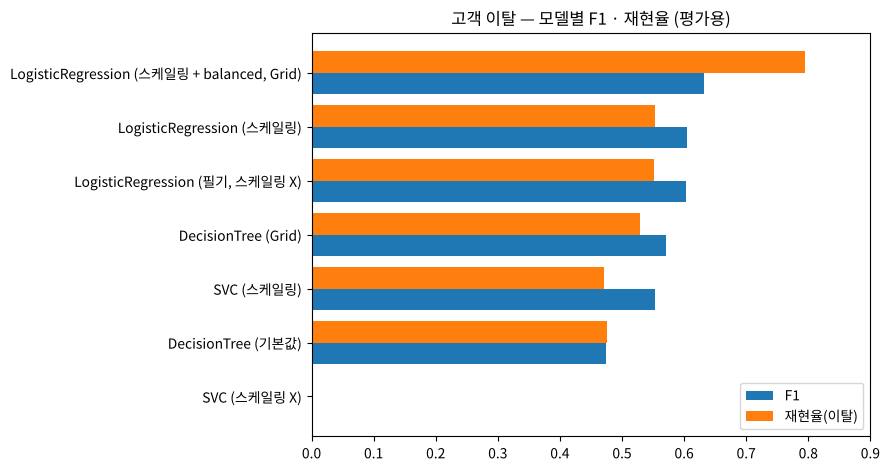

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.8))
res = results.sort_values('F1')
y = np.arange(len(res))
ax.barh(y - 0.2, res['F1'], height=0.4, label='F1')
ax.barh(y + 0.2, res['재현율'], height=0.4, label='재현율(이탈)')
ax.set_yticks(y, res.index)
ax.set_xlim(0, 0.9); ax.legend(loc='lower right')
ax.set_title('고객 이탈 — 모델별 F1 · 재현율 (평가용)')
plt.tight_layout()
plt.show()

![모델 비교](./images/06_churn_model_comparison.png)

- 이탈 예측은 **불균형** 문제라 정확도보다 **재현율 · F1** 로 비교한다. 정확도 1등(로지스틱 기본, 0.808)과 F1 1등(`balanced`, 0.632)이 다르다.
- 튜닝(`GridSearchCV`)보다 **전처리(스케일링)** 와 **문제에 맞는 설정(`class_weight`)** 의 효과가 훨씬 컸다.
- 모델을 고른 뒤에는 **내장 vs 순열 특성 중요도**로 "무엇을 근거로 예측하는가"를 확인한다 — 이 데이터에서는 **가입 기간 · 계약 형태 · 인터넷 서비스 종류**가 이탈의 핵심 근거.